# DQN and Dyna-DQN: mixed driving scenarios over 2,000 m

Train **2,000 additional episodes per model (4,000 total)**. Both start from the same saved 1,000-episode DQN Q weights, with fresh optimizers and replay. The route is **2,000 m within 90 seconds**, with all 18 sensors on. Driving is the only objective; sensor-energy and uncertainty reward weights remain zero.

The curriculum varies starting lanes, slower lead vehicles, blocked passing lanes, repeated traffic density, traffic speeds, and later rain/fog sensor degradation. It addresses the failures in the preceding frozen-policy evaluation. Traffic vehicles hold their lanes; cut-ins are not included.

This notebook **attaches to the launched study by default**. Run the monitoring cells again to refresh results. The workers continue after the notebook kernel closes. A fresh study launches only when `RUN_TRAINING=True`.

In [1]:
from pathlib import Path
from dataclasses import asdict
import json, sys, os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd() / "final_project", Path.cwd(), *Path.cwd().parents]
            if (p / "environments/sensor_highway/driving_curriculum.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from algorithms.curriculum_driving import CurriculumSettings
from environments.sensor_highway.driving_curriculum import SCENARIOS
from experiments.train_driving_curriculum import create_study, launch_workers, DEFAULT_RUN

settings = CurriculumSettings(episodes=2000)
ROUTE_M = 2000.
DEADLINE_S = 90.
TRAINING_SEED = 42
TRAFFIC_SEED_START = 2000000
SOURCE_RUN = DEFAULT_RUN
RUN_TRAINING = False
ACTIVE_FILE = ROOT / "runs/local/driving_curriculum_2000m/active_study.json"
STUDY = Path(json.loads(ACTIVE_FILE.read_text())["study"]) if ACTIVE_FILE.exists() else ROOT / "runs/exploratory/driving_curriculum_2000m/20261121_121917_066494"
print("Interpreter:", sys.executable)
print("New training budget:", settings.episodes, "per model;", 2 * settings.episodes, "total")
print("Attached study:", STUDY)
display(pd.Series(asdict(settings), name="Editable settings for a NEW study"))

Interpreter: /Users/zac/Desktop/Reinforcment_Learning/final_project/.venv/bin/python
New training budget: 2000 per model; 4000 total
Attached study: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/driving_curriculum_2000m/20261121_121917_066494


episodes                      2000
gamma                         0.99
alpha                         0.12
epsilon_start                  0.6
epsilon_end                   0.05
learning_rate               0.0001
hidden_size                     64
batch_size                      32
replay_capacity              50000
learning_starts                256
target_update_steps            100
planning_steps                   1
model_learning_starts         1000
double_q                      True
validation_interval            100
min_validation_terminals         5
feature_mae_limit             0.05
reward_mae_limit              0.02
terminal_mae_limit            0.15
q_abort_limit                 20.0
model_learning_rate          0.001
model_hidden_size              128
planning_loss_weight          0.25
occupancy_mae_limit           0.12
min_model_validation            64
Name: Editable settings for a NEW study, dtype: object

## Shared controls and curriculum

Both agents use masked Double-DQN targets, learning rate 0.0001, gamma 0.99, and the same 123 sensor/controller features as the earlier driving models. Ego localization and commanded lane/speed remain assumed measurements; traffic truth is not a policy input.

The controller mask applies consistently to exploration, greedy actions and Bellman targets. It excludes moves beyond the road edges, new lateral commands while a lane change is still active, and speed commands beyond the configured target range. Braking, acceleration and IDLE remain available during a lane change. These changes apply equally to both agents.

Every episode is 2 km. The first 20% use varied lead cars, left/right blockers and sparse repeated traffic. The next 30% add medium density and mixed speeds. The final 50% emphasize dense repeated encounters while retaining earlier cases. Stage one is clear; later stages sample 80% clear, 10% rain and 10% fog. Weather affects sensing, not road friction.

Progress reward is 0.001/m, time cost 0.002/s, finish bonus +1, early-finish bonus up to 0.1, and terminal failure −2. No oscillation penalty is added. Traffic seeds and scenario schedules match across algorithms, although their actions produce different trajectories.

In [2]:
scenario_table = pd.DataFrame([
    {"scenario": name, "traffic_type": spec[0], "spacing_m": spec[1],
     "traffic_speed_min": spec[2], "traffic_speed_max": spec[3]}
    for name, spec in SCENARIOS.items()
])
display(scenario_table)
print("Required mean forward speed:", ROUTE_M / DEADLINE_S, "m/s")

,scenario,traffic_type,spacing_m,traffic_speed_min,traffic_speed_max
0,varied_lead,varied_lead,420.0,18.0,22.0
1,blocked_left,blocked_left,420.0,18.0,22.0
2,blocked_right,blocked_right,420.0,18.0,22.0
3,repeated_sparse,repeated,420.0,18.0,22.0
4,repeated_medium,repeated,320.0,18.0,22.0
5,repeated_dense,repeated,260.0,18.0,22.0
6,repeated_mixed_speed,repeated,320.0,16.0,23.0


Required mean forward speed: 22.22222222222222 m/s


## What planning means in this experiment

Dyna trains a separate neural model to predict the next feature vector and nonterminal shaping reward. The known controller-command transition is applied analytically. Every tenth **entire episode** is excluded from model fitting for validation; the Q-network still learns its real transitions.

After at least 1,000 model-training transitions and 64 held-out transitions, planning requires feature MAE ≤0.05, occupancy-feature MAE ≤0.12 and reward MAE ≤0.02. Passing the gate permits **one one-step imagined batch per real step**, with loss weight 0.25. Poor later validation disables planning again. Imagined transitions never enter real replay.

Rollouts start only from **real nonterminal state/action pairs**, using the same observed action, so the one-step terminal flag is anchored to that real transition. Terminal crashes, deadline failures and completion bonuses are learned through real Q replay. This avoids the earlier terminal predictor blocking all planning. It is **not** a model of arbitrary termination or a multi-step generative rollout. `planning_steps` counts imagined batches, not rollout depth.

Compare both real environment steps and planning updates when interpreting results. A positive planning count confirms that Dyna ran; it does not by itself establish improved driving.

## Launch or attach

The following cell normally attaches to the current study. To create another run, edit the settings above, set `RUN_TRAINING=True`, then run this cell. That starts two background workers in a fresh output folder. Original checkpoints, previous results and stopped long-route studies remain separate.

Checkpoint state is saved every 25 episodes and at completion. Training metrics update each episode. Both models receive the same warm-start weights; this paired run uses one training initialization seed.

In [3]:
if RUN_TRAINING:
    STUDY = create_study(settings, source=SOURCE_RUN, seed=TRAINING_SEED,
                         train_seed_start=TRAFFIC_SEED_START,
                         route_m=ROUTE_M, deadline_s=DEADLINE_S)
    launch_workers(STUDY)
    ACTIVE_FILE.parent.mkdir(parents=True, exist_ok=True)
    ACTIVE_FILE.write_text(json.dumps({"study": str(STUDY)}, indent=2) + "\n")
else:
    print("Attaching; no new workers launched.")
if STUDY is not None:
    protocol = json.loads((STUDY / "protocol.json").read_text())
    print("Study:", STUDY)
    print("Actual additional episodes per model:", protocol["settings"]["episodes"])
    print("Route / deadline:", protocol["route_m"], "m /", protocol["deadline_s"], "s")
    print("Common source:", protocol["source_run"])
    print("Warm-start SHA256:", protocol["warm_start_sha256"])

Attaching; no new workers launched.
Study: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/driving_curriculum_2000m/20261121_121917_066494
Actual additional episodes per model: 2000
Route / deadline: 2000.0 m / 90.0 s
Common source: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/driving_policy_v1/driving_500ep_20261121_103801_682209
Warm-start SHA256: 971acf676c25beecdcf5441ad706c86add7aa3e19859189ff527ac41095d0f72


## Refresh live metrics

Training includes exploratory actions, so training completion is separate from frozen development evaluation. Checkpoints evaluate three fresh development seeds per scenario every 250 episodes. Final evaluation uses ten different held-out seeds per scenario, plus rain/fog on the medium repeated-traffic case. The old 300000 evaluation seeds are not used for training.

Re-run the following cells to refresh. A model may be in warm-up or briefly have planning disabled when the traffic distribution changes.

In [4]:
histories = {}
statuses = []
if STUDY is not None:
    for policy in ["dqn", "dyna_dqn"]:
        folder = STUDY / policy
        status = json.loads((folder / "status.json").read_text())
        statuses.append({"policy": policy, **{k: v for k, v in status.items() if k != "model_diagnostics"}})
        if (folder / "training.csv").exists():
            histories[policy] = pd.read_csv(folder / "training.csv")
        if status.get("model_diagnostics"):
            display(pd.Series(status["model_diagnostics"], name=f"{policy}: held-out model errors"))
    display(pd.DataFrame(statuses))
    rows = []
    for policy, h in histories.items():
        rows.append({"policy": policy, "episodes": len(h), "training_completions": int(h.completed.sum()),
            "training_crashes": int(h.crashed.sum()), "deadline_failures": int(h.deadline_failure.sum()),
            "real_steps": int(h.steps.sum()), "real_Q_updates": int(h.real_q_updates.iloc[-1]),
            "planning_updates": int(h.planning_updates.iloc[-1]),
            "imagined_transitions": int(h.imagined_transitions.iloc[-1]),
            "max_abs_Q": h.max_abs_q.max(), "training_wall_s": h.training_wall_s.iloc[-1]})
    display(pd.DataFrame(rows))

model_feature_mae           0.042382
model_reward_mae            0.003042
model_occupancy_mae         0.079386
model_validation_count    199.000000
Name: dyna_dqn: held-out model errors, dtype: float64

,policy,phase,episode,episodes,scenario,weather,stage,planning_updates,planning_allowed,max_abs_q,training_wall_s,pid
0,dqn,training,27,2000,varied_lead,clear,0,0,False,0.596896,35.693072,37855
1,dyna_dqn,training,22,2000,blocked_right,clear,0,612,True,0.672927,34.341286,37856


,policy,episodes,training_completions,training_crashes,deadline_failures,real_steps,real_Q_updates,planning_updates,imagined_transitions,max_abs_Q,training_wall_s
0,dqn,27,6,19,2,1901,1646,0,0,2.348713,35.693072
1,dyna_dqn,22,5,14,3,1811,1556,612,19584,2.348713,34.341286


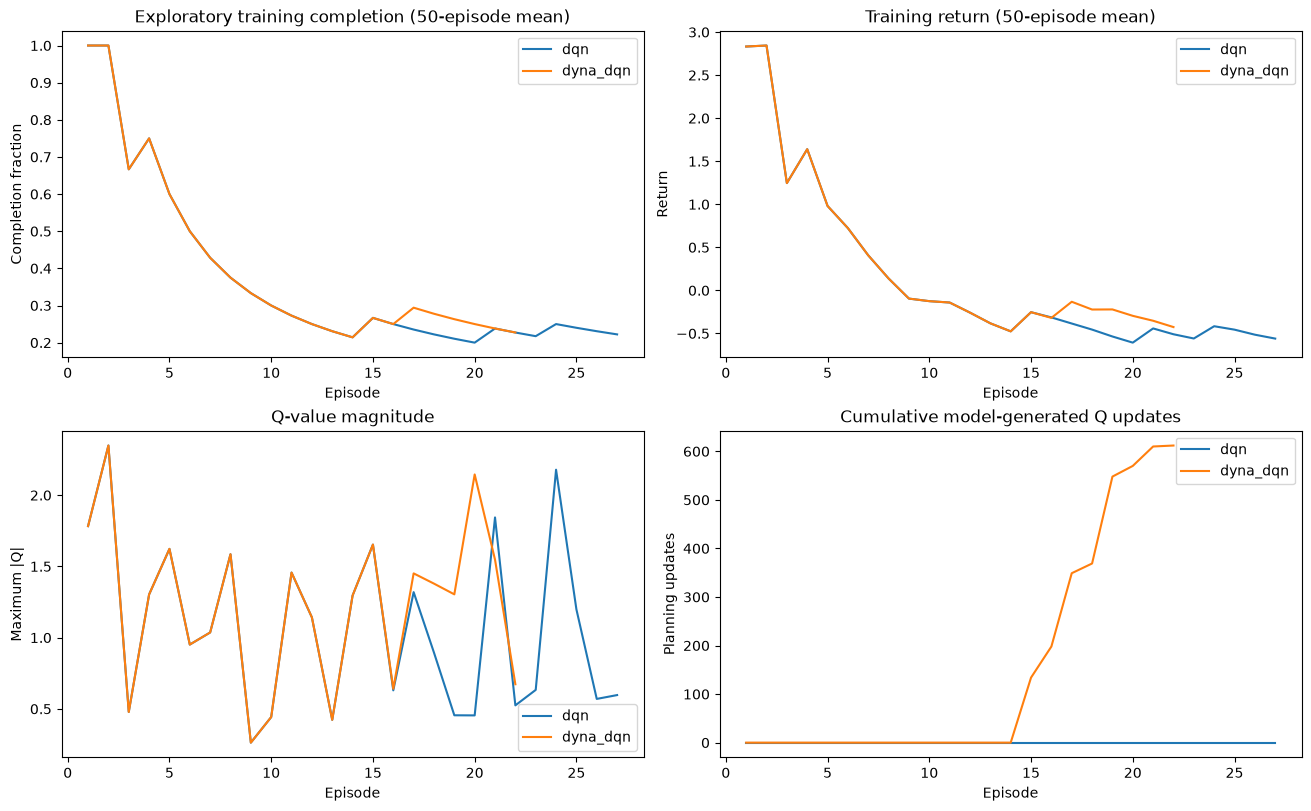

In [5]:
if histories:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for policy, h in histories.items():
        axes[0,0].plot(h.episode, h.completed.rolling(50, min_periods=1).mean(), label=policy)
        axes[0,1].plot(h.episode, h["return_"].rolling(50, min_periods=1).mean(), label=policy)
        axes[1,0].plot(h.episode, h.max_abs_q, label=policy)
        axes[1,1].plot(h.episode, h.planning_updates, label=policy)
    for ax, title, ylabel in zip(axes.flat,
            ["Exploratory training completion (50-episode mean)", "Training return (50-episode mean)",
             "Q-value magnitude", "Cumulative model-generated Q updates"],
            ["Completion fraction", "Return", "Maximum |Q|", "Planning updates"]):
        ax.set(title=title, xlabel="Episode", ylabel=ylabel)
        ax.legend()
    fig.savefig(STUDY / "live_training.png", dpi=150)
    display(fig)
    plt.close(fig)

In [6]:
if STUDY is not None:
    for policy in ["dqn", "dyna_dqn"]:
        folder = STUDY / policy
        for filename in ["development_summary.csv", "final_summary.csv"]:
            path = folder / filename
            if path.exists():
                print(policy, filename)
                display(pd.read_csv(path))
        replay = folder / "replay/replay.html"
        if replay.exists():
            relative = os.path.relpath(replay, ROOT / "experiments")
            display(Markdown(f"[{policy}: final evaluation replay]({relative})"))

## Stop and resume

Create a file named `STOP` in the study directory to request a clean stop after the current episode. Both workers checkpoint before stopping. Remove that marker only when you intend to resume, then call `launch_workers(STUDY)`; it loads the full saved training state. Do not edit protocol or source files for an existing study. Changed hyperparameters require a new study.

```python
# Request a stop explicitly:
# (STUDY / "STOP").touch()

# Resume explicitly after the workers have stopped:
# (STUDY / "STOP").unlink(missing_ok=True)
# launch_workers(STUDY)
```

Interpret success using frozen completion/crash/deadline metrics by scenario, overtakes, lane changes, Q stability and actual planning counts. Once this driving stage is reliable across independent training seeds, sensor scheduling can be introduced in a separate experiment.